# EMQA_L6_shape15

**Intraday shape of the Romanian day-ahead price at 15-min resolution: mean price of each of the 96 quarter-hours (CET) by season over the last 12 months, 2025-11-01 to 2026-10-31. Prints the spring minimum and maximum (with their times) and the daily range of spring, summer and winter.**

Energy Markets Quantitative Analysis (EMQA), Lecture 6 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L6/EMQA_L6_shape15/EMQA_L6_shape15.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

## Setup: chart style and data period

In [2]:
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

# course chart style: transparent background, no grid, legend at the bottom outside the axes, fixed colour per zone
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}
ZONE_LS = {'RO': '-', 'BG': '--', 'HU': '-.', 'DE_LU': ':'}
ZN = {'RO': 'Romania', 'BG': 'Bulgaria', 'HU': 'Hungary', 'DE_LU': 'Germany-Lux.'}
INK = '#222222'
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': INK, 'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK,
    'text.color': INK, 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})


def legend_bottom(fig, ncol=4):
    """One legend for the whole figure, centred under the axes, outside the plotting area."""
    handles, labels = [], []
    for ax in fig.axes:
        for h, l in zip(*ax.get_legend_handles_labels()):
            if l not in labels:
                handles.append(h)
                labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0), frameon=False,
               handlelength=2.0, columnspacing=1.2)


def fl(x, k=4):
    """Rounding used for the numbers of the slides."""
    return None if x is None or np.isnan(float(x)) else round(float(x), k)


def show_numbers(d):
    for k, v in d.items():
        print(f'{k:<34} {v}')

Mean price of quarter-hour slot k = 4 x hour + minute / 15 over the days of each season (meteorological seasons).

In [3]:
TZ = 'Europe/Brussels'                     # delivery days in CET/CEST
END = pd.Timestamp('2026-10-31')               # cut-off of Lecture 6 = last complete month of the data
END_X = (END + pd.Timedelta(days=1)).tz_localize(TZ)
Y = END.year
YEARS = list(range(2019, Y + 1))
MON_EN = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
YTD = f'* {Y} = Jan-{MON_EN[END.month - 1]}'
LTM0 = pd.Timestamp('2025-11-01').tz_localize(TZ)    # first day of the last 12 months
MTU15 = pd.Timestamp('2025-10-01').tz_localize(TZ)   # 15-min market time unit from 1 Oct 2025

In [4]:
# day-ahead prices, EUR/MWh: hourly to 30 Sep 2025, 15-min from 1 Oct 2025 (SDAC); index in CET/CEST
PX = pd.read_csv(DATA + 'power_da_prices_native_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
PX.index = PX.index.tz_convert(TZ)
PX['dur'] = PX['mtu_minutes'] / 60.0          # interval length in hours
PX = PX[PX.index < END_X]
LOC_YEAR = PX.index.year
print('prices:', PX.index.min(), 'to', PX.index.max(), '|', (PX['mtu_minutes'] == 15).sum(), '15-min intervals')

prices: 2015-01-01 01:00:00+01:00 to 2026-10-31 23:45:00+01:00 | 38020 15-min intervals


In [5]:
qq = PX.loc[(PX.index >= LTM0) & (PX.index >= MTU15), ['RO']].copy()
qq['slot'] = qq.index.hour * 4 + qq.index.minute // 15
SEAS = {'winter': [12, 1, 2], 'spring': [3, 4, 5], 'summer': [6, 7, 8], 'autumn': [9, 10, 11]}
PROF = {s: qq[qq.index.month.isin(ms)].groupby('slot')['RO'].mean() for s, ms in SEAS.items()}
hm = lambda k: f'{k // 4:02d}:{k % 4 * 15:02d}'
sp = PROF['spring']
show_numbers({'shape.spring.min': fl(sp.min(), 1), 'shape.spring.min_t': hm(sp.idxmin()),
              'shape.spring.max': fl(sp.max(), 1), 'shape.spring.max_t': hm(sp.idxmax()),
              'shape.spring.range': fl(sp.max() - sp.min(), 1), 'shape.summer.range': fl(PROF['summer'].max() - PROF['summer'].min(), 1),
              'shape.winter.range': fl(PROF['winter'].max() - PROF['winter'].min(), 1)})

shape.spring.min                   23.0
shape.spring.min_t                 12:45
shape.spring.max                   208.3
shape.spring.max_t                 19:45
shape.spring.range                 185.3
shape.summer.range                 225.6
shape.winter.range                 97.8


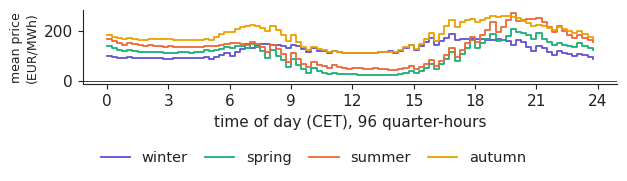

In [6]:
fig, ax = plt.subplots(figsize=(6.4, 1.85))
SL = {'winter': 'winter', 'spring': 'spring', 'summer': 'summer', 'autumn': 'autumn'}   # Dec-Feb, Mar-May, Jun-Aug, Sep-Nov
SC = {'winter': PAL['c7'], 'spring': PAL['HU'], 'summer': PAL['DE_LU'], 'autumn': PAL['BG']}
for s_, pr in PROF.items():
    ax.step(np.arange(96) / 4, pr.values, where='post', color=SC[s_], lw=1.3, label=SL[s_])
ax.axhline(0, color=INK, lw=0.6)
ax.set_xticks(range(0, 25, 3))
ax.set_xlabel('time of day (CET), 96 quarter-hours')
ax.set_ylabel('mean price\n(EUR/MWh)', fontsize=9)
legend_bottom(fig, ncol=4)
fig.canvas.draw()
legend_h = max([lg.get_window_extent().height for lg in fig.legends] or [0.0]) / fig.bbox.height
fig.tight_layout(rect=(0, legend_h + 0.035, 1, 1))
plt.savefig('shape15.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()